# Map-to-Map Change Detection

*Section 6 — Change detection, notebook 2 of 5.* Previous: `01_create_baseline_class`. Next: `03_image_to_image_change`.

**You will learn:**
- how to classify a second image (2018) with the same class definitions as the baseline;
- how to fill gaps (e.g., cloud) in one classification from another with `band_maths`;
- how to compare two classifications to create a from–to change map, with class names and colours stored in the image by `set_thematic_classes`;
- how to draw several maps side by side with `create_map_panels`.

**Before you start:** run `01_create_baseline_class` first; this notebook reads its 1997 classification and valid-data mask from `outputs/baseline_cls`.

**Data:** `../data/chg_data/LS8_20180608_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif` (Landsat 8, 2018), `../data/chg_data/LS5TM_19970716_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif` (Landsat 5 TM, 1997), `../data/chg_data/training/2018/*.geojson` and `../data/chg_data/mangrove_habitat.geojson`.

**Run time:** about 1 minute.

## Introduction

Change detection is a *hot* topic within the Earth Observation (EO) community, particularly since the release of the Landsat archive and more recently the availability of the ESA Sentinel-1 and 2 data.

There are several approaches to change detection and these can be categorised as:

- Map-to-Map
- Image-to-Image
- Map-to-Image
- Dense Timeseries

These approaches have different advantages and disadvantages and this section will demonstrate the implementation of a method for each type.

## What is Map-to-Map Change?

Map-to-Map change detection processes compare two classified maps and where they differ a change has occurred. These approaches can be very **sensitive to mis-classification** in one or both of the classifications. As you probably already know, classification results, even very good ones (i.e., accuracies > 90 %), still have errors and these are often different between two or more classifications. Therefore, false changes can easily be identified. However, the two classifications can be derived using any method, using any data you like as long as they use **the same class definitions**, or from data of different seasons. We can therefore say that this approach is **input EO data invariant**.

## What are the steps:

This is quite a simple method, basically we just need to undertake another classification but this time use the 2018 image as the input. Once the classification of the 2018 input image is complete then we can compare the two classifications to undertake the change detection.

## 1. Define Imports

In [1]:
# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline

import os

import matplotlib.pyplot as plt

import rsgispy
import rsgispy.classification.classxgboost as cxgb
from rsgispy.classification.classdata import (
    ClassificationConfig,
    ClassInfoObj,
    ImageBandInfo,
    extract_and_split_class_samples,
    write_cls_config,
)
from rsgispy.imagecalc.maths import BandDefn, band_maths
from rsgispy.imageutils.colourtable import get_thematic_classes, set_thematic_classes
from rsgispy.imageutils.masking import gen_valid_mask
from rsgispy.imageutils.rasterise import rasterise_vec_lyr
from rsgispy.mapping.layout import MapPanel, create_map_panels
from rsgispy.mapping.raster import create_thematic_raster_map

## 2. Define Input Data and Directories

In [2]:
out_dir = os.path.join("outputs", "2018_cls")
os.makedirs(out_dir, exist_ok=True)

# The outputs of notebook 01.
baseline_dir = os.path.join("outputs", "baseline_cls")

map_to_map_chg_dir = os.path.join("outputs", "map_to_map_chg")
os.makedirs(map_to_map_chg_dir, exist_ok=True)

# File path to the input Landsat 8 image from 2018.
input_img = (
    "../data/chg_data/LS8_20180608_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif"
)

# Note the Landsat 8 image has an extra image band (coastal) over the older
# Landsat 5 sensor.
img_band_info = [
    ImageBandInfo(
        input_img,
        name="ls18",
        bands=[1, 2, 3, 4, 5, 6, 7],
        band_names=["Coastal", "Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2"],
    )
]

## 3. Define Training Samples and Class Colours

You need to make sure that the output pixel values (i.e., the `out_id`) are the same as the baseline classification otherwise when you come to compare the classifications it might be confusing and difficult.

In [3]:
class_info = {
    "mangroves": ClassInfoObj(
        out_id=1,
        vec_file="../data/chg_data/training/2018/mangroves.geojson",
        colour=(0, 255, 0),
    ),
    "other_terrestrial": ClassInfoObj(
        out_id=2,
        vec_file="../data/chg_data/training/2018/other_terrestrial.geojson",
        colour=(180, 180, 180),
    ),
    "water": ClassInfoObj(
        out_id=3,
        vec_file="../data/chg_data/training/2018/water.geojson",
        colour=(0, 0, 255),
    ),
}

cls_cfg = ClassificationConfig(img_band_info, class_info)
write_cls_config(os.path.join(out_dir, "cls_config.json"), cls_cfg)
print(cls_cfg.get_class_names_lut())

{1: 'mangroves', 2: 'other_terrestrial', 3: 'water'}


## 4. Extract Training, Validation and Testing Samples

In [4]:
train_file = os.path.join(out_dir, "train.parquet")
valid_file = os.path.join(out_dir, "valid.parquet")
test_file = os.path.join(out_dir, "test.parquet")

train_df, test_df, valid_df = extract_and_split_class_samples(
    cls_cfg,
    test_prop=0.2,
    valid_prop=0.2,
    out_train_file=train_file,
    out_test_file=test_file,
    out_valid_file=valid_file,
    max_cls_smpls=20000,
    rnd_seed=42,
    use_pbar=False,
)

## 5. Number of Samples

Check the number of samples there are per class in each of the training, validation and testing sets.

In [5]:
for name, smpls_df in (("train", train_df), ("valid", valid_df), ("test", test_df)):
    print(name, smpls_df["class_name"].value_counts().to_dict())

train {'mangroves': 12000, 'other_terrestrial': 12000, 'water': 12000}
valid {'mangroves': 4000, 'other_terrestrial': 4000, 'water': 4000}
test {'mangroves': 4000, 'other_terrestrial': 4000, 'water': 4000}


## 6. Define Classification Mask

Mangroves have a unique habitat being close to the coastline with a low elevation. It is therefore not appropriate to look to classify mangroves in other locations. In this case we will use a mangrove habitat mask similar to that used as part of the global mangrove watch study (Bunting et al., 2018).

### 6.1 Rasterise Mangrove Habitat Mask

In [6]:
vec_file = "../data/chg_data/mangrove_habitat.geojson"

mng_hab_msk_img = os.path.join(out_dir, "mangrove_habitat.tif")

rasterise_vec_lyr(vec_file, None, input_img, mng_hab_msk_img, burn_val=1, use_pbar=False)

### 6.2 Create Landsat Valid Mask

We need to check which pixels are valid within the Landsat image so only those with image pixel values are being used.

In [7]:
vld_pxl_msk_img = os.path.join(out_dir, "LS8_20180608_vmsk.tif")

# Calculate the valid mask (a thematic image: 1 = valid, 0 = no data).
gen_valid_mask(input_img, vld_pxl_msk_img, no_data_val=0.0, use_pbar=False)

### 6.3 Merge Habitat and Valid Pixel Masks

In [8]:
mng_scn_hab_msk_img = os.path.join(out_dir, "LS8_20180608_vmsk_mng_hab.tif")

# Create Mask for pixels which are valid and within the mangrove habitat mask.
band_defns = [
    BandDefn("vld", vld_pxl_msk_img, 1),
    BandDefn("hab", mng_hab_msk_img, 1),
]
band_maths(
    mng_scn_hab_msk_img,
    "(vld==1)&&(hab==1)?1:0",
    band_defns,
    datatype=rsgispy.TYPE_8UINT,
    use_pbar=False,
)

# Mark the binary mask as thematic, with a class name and colour, statistics
# and pyramids.
set_thematic_classes(mng_scn_hab_msk_img, {1: ("Mangrove habitat", (0, 160, 0))})

### 6.4 Visualise Mask

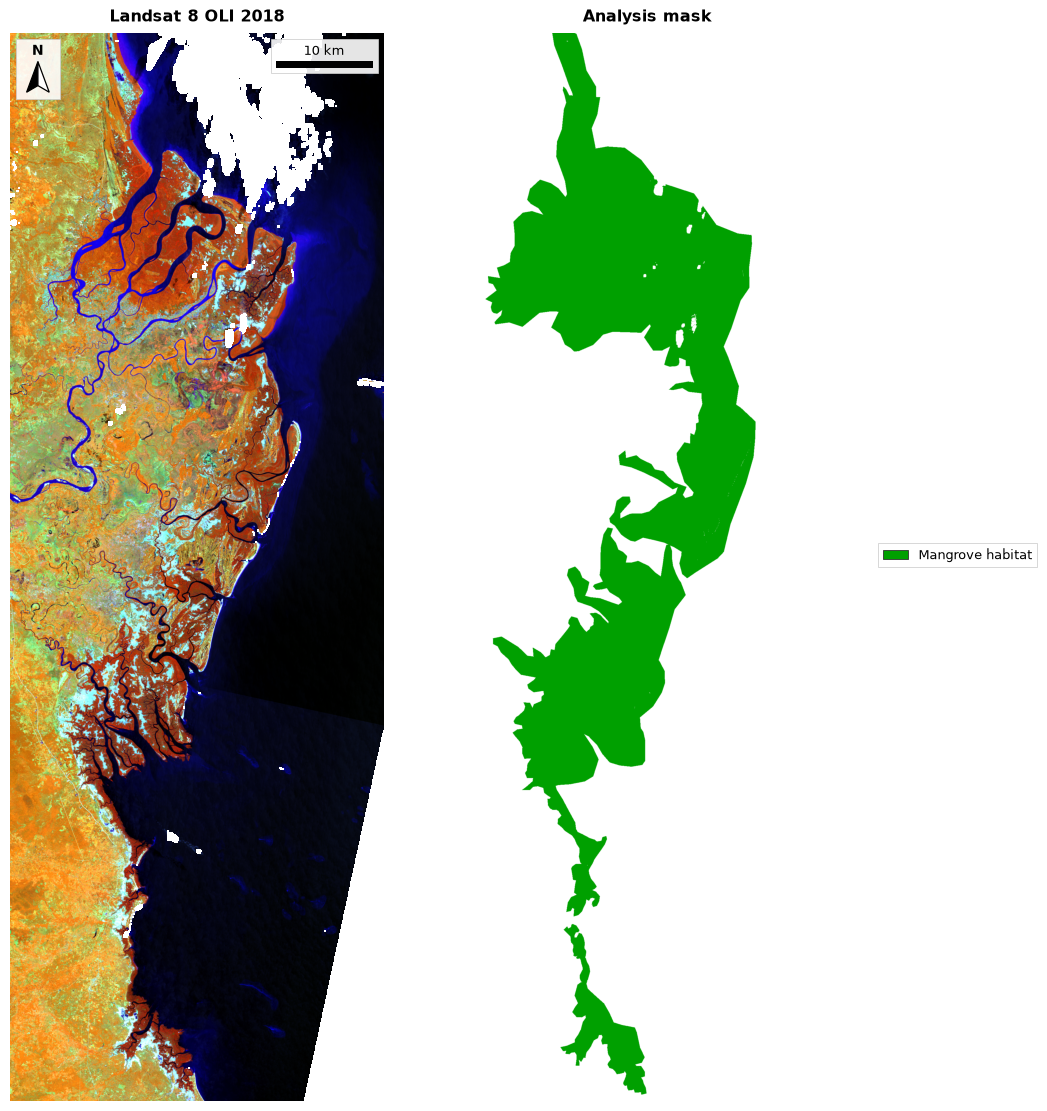

In [9]:
fig, axs = create_map_panels(
    [
        MapPanel("rgb", input_img, bands=[5, 6, 4], title="Landsat 8 OLI 2018"),
        MapPanel("thematic", mng_scn_hab_msk_img, title="Analysis mask"),
    ],
    figsize=(9, 11),
)

## 7. Train Classifier

As in notebook 01, the XGBoost parameters are tuned with a short Bayesian optimisation (10 trials, scored on the validation samples) and the final model is checked on the test samples.

In [10]:
xgb_model = cxgb.optimise_xgboost_multiclass_classifier(
    cls_cfg,
    train_file,
    valid_data=valid_file,
    n_trials=10,
    early_stopping_rounds=20,
    rnd_seed=42,
    use_pbar=False,
)

out_mdl_file = os.path.join(out_dir, "cls_xgb_mdl_2018.json")
_, xgb_metrics = cxgb.train_xgboost_multiclass_classifier(
    cls_cfg,
    train_file,
    test_data=test_file,
    xgb_classifier=xgb_model,
    out_model_file=out_mdl_file,
)
print({k: round(v, 3) for k, v in xgb_metrics.items()})

{'train_accuracy': 1.0, 'train_bal_accuracy': 1.0, 'train_f1_macro': 1.0, 'train_cohen_kappa': 1.0, 'test_accuracy': 0.994, 'test_bal_accuracy': 0.994, 'test_f1_macro': 0.994, 'test_cohen_kappa': 0.991}


## 8. Apply Classifier

As in notebook 01, the class names are stored in the classification with `set_thematic_classes` so the maps can label the classes.

In [11]:
cls_2018_img = os.path.join(out_dir, "class_2018_img.tif")
cxgb.apply_xgboost_multiclass_classifier(
    cls_cfg,
    out_mdl_file,
    mng_scn_hab_msk_img,
    1,
    output_img=cls_2018_img,
    use_pbar=False,
)
set_thematic_classes(
    cls_2018_img,
    {cls.out_id: (name, cls.colour) for name, cls in class_info.items()},
)

## 9. Visualise Classification Result

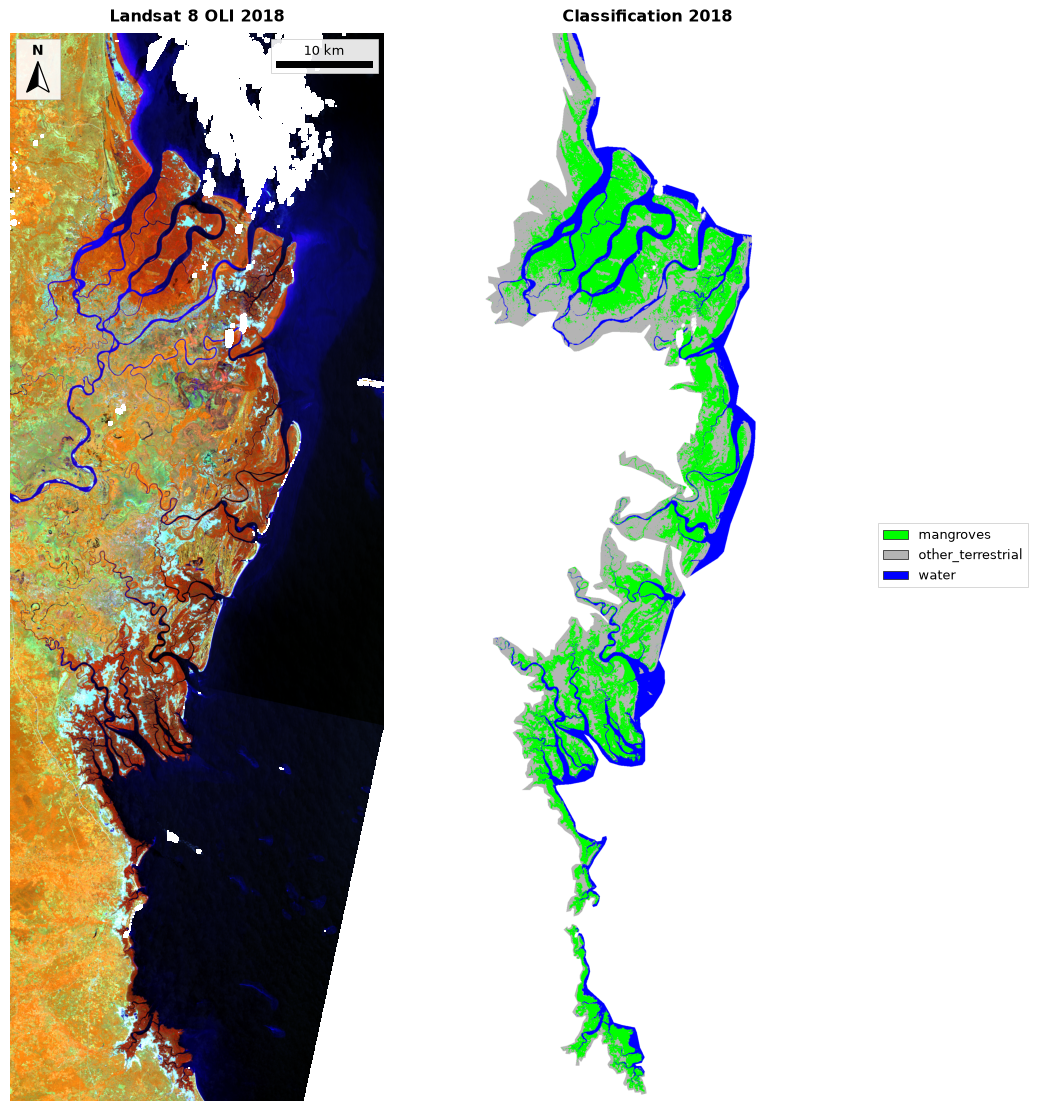

In [12]:
fig, axs = create_map_panels(
    [
        MapPanel("rgb", input_img, bands=[5, 6, 4], title="Landsat 8 OLI 2018"),
        MapPanel("thematic", cls_2018_img, title="Classification 2018"),
    ],
    figsize=(9, 11),
)

## 10. Visualise Subset

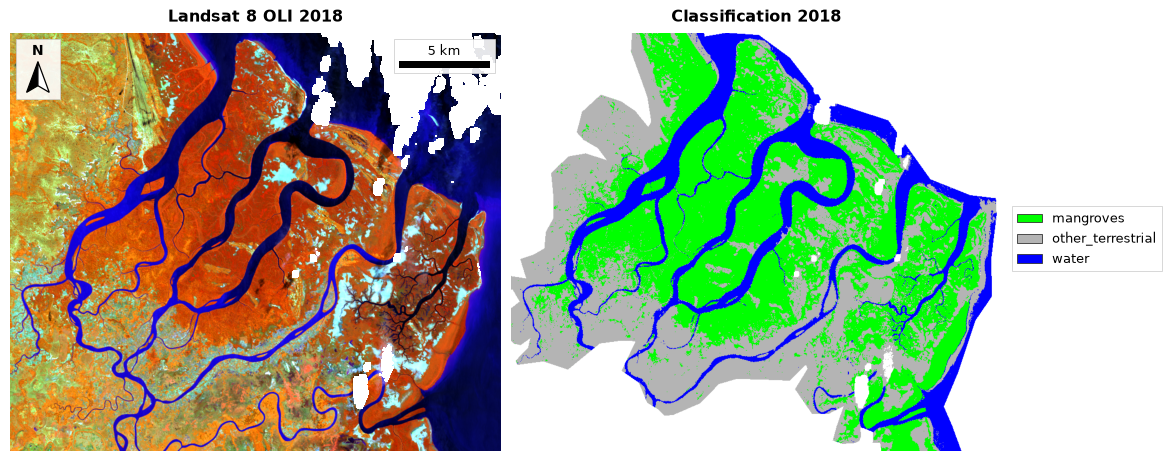

In [13]:
sub_bbox = [523000, 550000, -877000, -854000]

fig, axs = create_map_panels(
    [
        MapPanel("rgb", input_img, bands=[5, 6, 4], title="Landsat 8 OLI 2018"),
        MapPanel("thematic", cls_2018_img, title="Classification 2018"),
    ],
    bbox=sub_bbox,
)

## 11. Compare Classifications

### 11.1 Define the 1997 (baseline) file paths

In [14]:
# File path to the 1997 classification
cls_1997_img = os.path.join(baseline_dir, "base_1997_class_img.tif")

# File path to the input Landsat 5 image from 1997.
input_97_img = (
    "../data/chg_data/LS5TM_19970716_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif"
)

# File path to the Landsat 5 valid data mask from 1997
vld_97_img = os.path.join(baseline_dir, "LS5TM_19970716_vmsk.tif")

### 11.2 Visualise Classifications

The four maps share one extent, scale bar, north arrow and legend (the class names stored in both classifications).

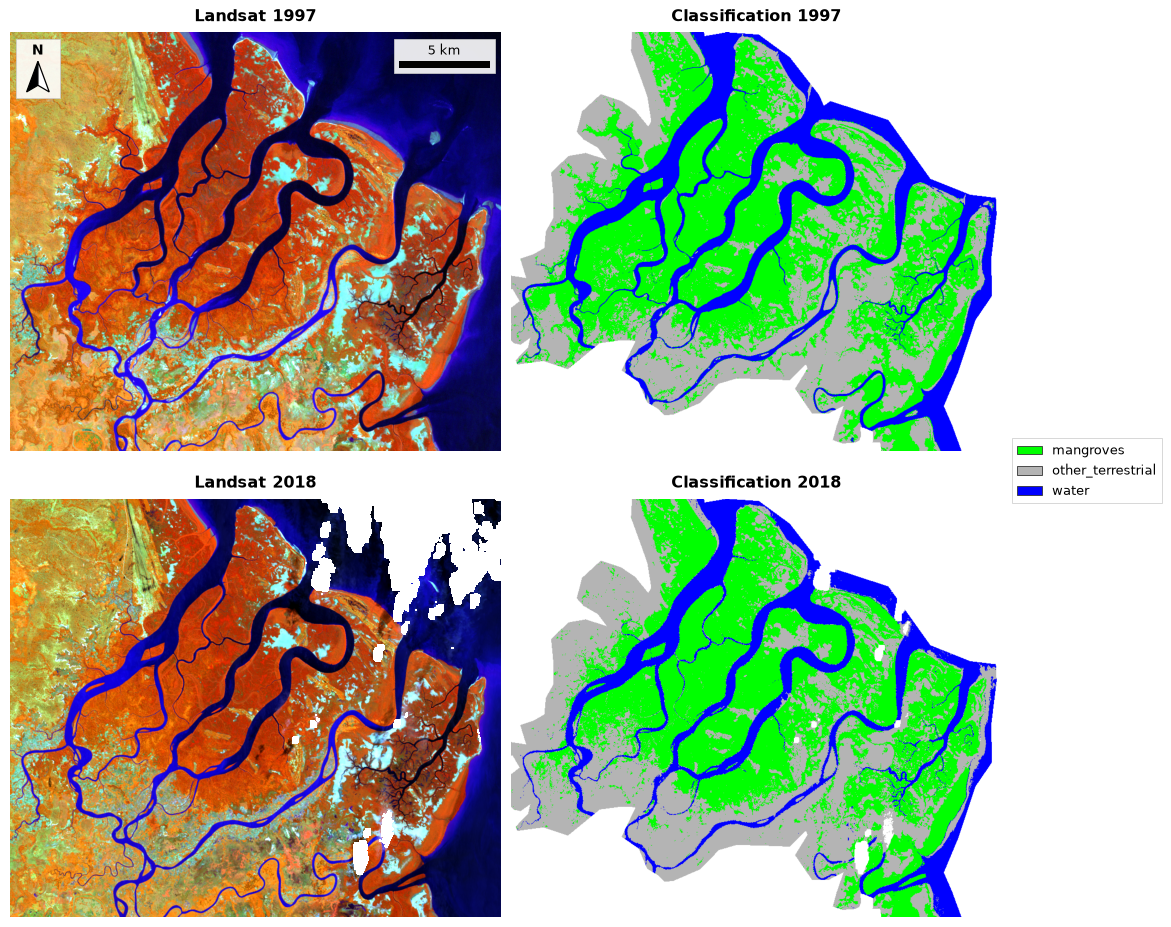

In [15]:
sub_bbox = [523000, 550000, -877000, -854000]

fig, axs = create_map_panels(
    [
        MapPanel("rgb", input_97_img, bands=[4, 5, 3], title="Landsat 1997"),
        MapPanel("thematic", cls_1997_img, title="Classification 1997"),
        MapPanel("rgb", input_img, bands=[5, 6, 4], title="Landsat 2018"),
        MapPanel("thematic", cls_2018_img, title="Classification 2018"),
    ],
    ncols=2,
    bbox=sub_bbox,
)

## 12. Fill 2018 Gaps

There are some gaps in the 2018 classification due to cloud cover. In this case, we will fill the 2018 classification using the result from the 1997 classification. Clearly for these regions there will be no change identified as the classification will be the same.

### 12.1 Using `band_maths` to perform the fill

`band_maths` evaluates a muparser-style expression (`&&`, `||` and the `? :` conditional) for every pixel, where each `BandDefn` names an image band used in the expression.

In [16]:
# Define output image path
cls_2018_filled_img = os.path.join(out_dir, "class_2018_fill_img.tif")

# Define the input image bands
band_defns = [
    BandDefn("vld_97_msk", vld_97_img, 1),
    BandDefn("vld_18_msk", vld_pxl_msk_img, 1),
    BandDefn("cls_1997", cls_1997_img, 1),
    BandDefn("cls_2018", cls_2018_img, 1),
]

# Expression to perform fill
exp = """(vld_18_msk==1)&&(vld_97_msk==1)?cls_2018:
         (vld_18_msk==0)&&(vld_97_msk==1)?cls_1997:0"""

# Run band_maths
band_maths(cls_2018_filled_img, exp, band_defns, datatype=rsgispy.TYPE_8UINT, use_pbar=False)


### 12.2 Add Classification Colours and Names

`set_thematic_classes` marks the image as thematic, writes the class colours to the image's colour table, stores the class names in the image (as a GeoTIFF band tag) and calculates the statistics and pyramids. The names can be read back with `get_thematic_classes`, and the mapping functions use them for their legends.

**RSGISLib users:** `rastergis.set_class_names_colours` wrote the names and colours to a raster attribute table; `imageutils.colourtable.set_thematic_classes` is its rsgispy equivalent (rsgispy does not use raster attribute tables).

In [17]:
# pixel value: (class name, (red, green, blue))
cls_info = {
    1: ("mangroves", (0, 255, 0)),
    2: ("other_terrestrial", (180, 180, 180)),
    3: ("water", (0, 0, 255)),
}
set_thematic_classes(cls_2018_filled_img, cls_info)
get_thematic_classes(cls_2018_filled_img)

{1: ('mangroves', '#00ff00'),
 2: ('other_terrestrial', '#b4b4b4'),
 3: ('water', '#0000ff')}

## 13. Create the Change Map

### 13.1 Use `band_maths` to calculate change

Each pixel is given a two digit code: the 1997 class followed by the 2018 class (e.g., 12 is mangrove in 1997 which became other terrestrial in 2018).

In [18]:
# Define output image path
chng_map_img = os.path.join(map_to_map_chg_dir, "chng_map_1997_2018_img.tif")

# Define the input image bands
band_defns = [
    BandDefn("cls_1997", cls_1997_img, 1),
    BandDefn("cls_2018", cls_2018_filled_img, 1),
]

# Expression to define change classes
exp = """(cls_1997==1)&&(cls_2018==1)?11:
         (cls_1997==1)&&(cls_2018==2)?12:
         (cls_1997==1)&&(cls_2018==3)?13:
         (cls_1997==2)&&(cls_2018==1)?21:
         (cls_1997==2)&&(cls_2018==2)?22:
         (cls_1997==2)&&(cls_2018==3)?23:
         (cls_1997==3)&&(cls_2018==1)?31:
         (cls_1997==3)&&(cls_2018==2)?32:
         (cls_1997==3)&&(cls_2018==3)?33:0
      """

# Run band_maths
band_maths(chng_map_img, exp, band_defns, datatype=rsgispy.TYPE_8UINT, use_pbar=False)


### 13.2 Define Change Colours and Names

In [19]:
# pixel value: (class name, (red, green, blue))
chng_cls_info = {
    11: ("Mangrove_Mangrove", (25, 200, 25)),
    12: ("Mangrove_Terrestrial", (200, 100, 25)),
    13: ("Mangrove_Water", (200, 25, 200)),
    21: ("Terrestrial_Mangrove", (125, 100, 125)),
    22: ("Terrestrial_Terrestrial", (125, 125, 125)),
    23: ("Terrestrial_Water", (125, 125, 100)),
    31: ("Water_Mangrove", (25, 255, 200)),
    32: ("Water_Terrestrial", (62, 62, 200)),
    33: ("Water_Water", (25, 25, 200)),
}

set_thematic_classes(chng_map_img, chng_cls_info)
chng_cls_names = {val: name for val, (name, _) in chng_cls_info.items()}

### 13.3 Visualise Change Map

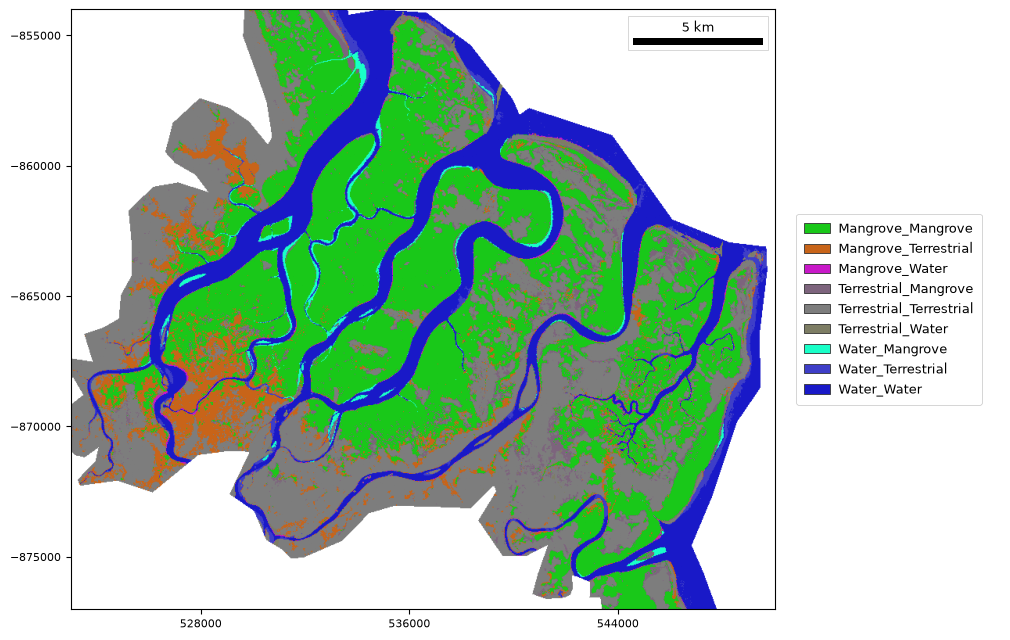

In [20]:
sub_bbox = [523000, 550000, -877000, -854000]

fig, ax = plt.subplots(figsize=(12, 10))

# Plot the change image; the legend uses the class names stored in the image
# and lists the change classes present.
img = create_thematic_raster_map(
    ax,
    chng_map_img,
    bbox=sub_bbox,
    show_legend=True,
    legend_ncols=1,
)

### 13.4 Change Areas

As the change map is a thematic image we can count the pixels in each change class and convert them to an area (the Landsat pixels are 30 x 30 m).

In [21]:
import numpy as np
import rasterio

with rasterio.open(chng_map_img) as ds:
    chng_arr = ds.read(1)
    pxl_area_ha = abs(ds.res[0] * ds.res[1]) / 10000.0

for val, name in chng_cls_names.items():
    print(f"{name:>24}: {np.sum(chng_arr == val) * pxl_area_ha:10.1f} ha")

       Mangrove_Mangrove:    32643.8 ha
    Mangrove_Terrestrial:     4090.2 ha
          Mangrove_Water:      683.5 ha
    Terrestrial_Mangrove:     4439.2 ha
 Terrestrial_Terrestrial:    30464.7 ha
       Terrestrial_Water:      644.7 ha
          Water_Mangrove:      745.6 ha
       Water_Terrestrial:     1690.4 ha
             Water_Water:    16338.4 ha
